# Titanic Dataset: Exploratory Data Analysis & Baseline Benchmarking

## Executive Summary
This project represents the first phase of an end-to-end Machine Learning pipeline designed to predict passenger survival during the RMS Titanic disaster.

The primary objectives of this notebook are:
1. **Identify data structures and audit missing values (Missing Values Profiling).**
2. **Establish an unmanipulated baseline model benchmark (Naive Baseline)** to determine a reference performance floor for subsequent feature engineering iterations.
3. **Conduct deep statistical profiling of numeric distributions (Skewness, Kurtosis, and Outlier Analysis via IQR).**
4. **Validate domain assumptions for advanced feature engineering** (e.g., title extraction from passenger names, ticket decomposition, and family/group size estimation).

---

## Tech Stack & Environment
* **Core Libraries**: `pandas`, `numpy`, `scipy`
* **Data Visualization**: `matplotlib`, `seaborn`
* **Machine Learning**: `scikit-learn` (`LogisticRegression`, `RandomForestClassifier`, `SVC`, `KNeighborsClassifier`), `xgboost` (`XGBClassifier`)
* **Explainability & Optimization**: `optuna`, `shap`

In [2]:
import os
import pandas as pd  
import numpy as np  
import matplotlib.pyplot as plt 
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from scipy import stats
from IPython.display import display
import Train_metric 
import optuna
import shap

## Data Loading & Structural Integrity Audit

Load the `Titanic-Dataset.csv` file and create a working copy (`df_benchmark`) to establish a minimal baseline before executing deep data transformations.

Integrity checks performed:
* Identification of duplicate records,
* Feature data types (`Dtype`) and cardinality/uniqueness (`nunique`),
* Missing value density (`isnull`),
* Summary descriptive statistics (`describe()`).

In [3]:
# Loading the dataset, check the first 5 rows to confirm
filepath = 'Titanic-Dataset.csv'
df = pd.read_csv(filepath)
df_benchmark = df.copy()
print(df_benchmark.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  


In [4]:
duplicates = df.duplicated().sum()
if duplicates > 0:
    print(f"Duplicates found. Duplicate count: {duplicates}.")
else:
    print("No duplicates found.")
print(40*"-")

print(pd.DataFrame
      (
          {
              "Unique count": df.nunique(),
              "Dtype": df.dtypes,
              "Num of missing values": df.isnull().sum()
          }
      )
     )
print(40*"-")
print(f"Basic dataset info:\n{df.describe()}")

No duplicates found.
----------------------------------------
             Unique count    Dtype  Num of missing values
PassengerId           891    int64                      0
Survived                2    int64                      0
Pclass                  3    int64                      0
Name                  891   object                      0
Sex                     2   object                      0
Age                    88  float64                    177
SibSp                   7    int64                      0
Parch                   7    int64                      0
Ticket                681   object                      0
Fare                  248  float64                      0
Cabin                 147   object                    687
Embarked                3   object                      2
----------------------------------------
Basic dataset info:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.00000

### Key Findings from Initial Audit:
* **Dataset Shape**: 891 rows and 12 features; no duplicate rows detected.
* **Target Distribution (`Survived`)**: Baseline survival rate is **38.38%** (342 survivors vs. 549 fatalities). The target is moderately balanced, allowing the use of standard metrics such as `Accuracy` and `ROC-AUC`.
* **Missing Value Profiling**:
  * `Cabin`: **687 missing values (77.1%)** – too sparse for straightforward numerical imputation; ideal for binary indicators (`HasCabin`) and deck extraction (`Deck`).
  * `Age`: **177 missing values (19.86%)** – requires context-aware conditional imputation to prevent artificial variance distortion caused by a naive global median.
  * `Embarked`: **2 missing values (0.22%)** – suitable for simple mode imputation.
* **Heavily Skewed Variables**:
  * `Fare`: The mean is 32.20 while the median sits at 14.45 (maximum value: 512.33). Severe right-tail skewness indicates the need for log transformation or robust tree-based partitioning.

---
## Naive Baseline Pre-processing

To set an empirical performance floor, we construct a minimal, naive version of the feature space:
1. Drop unstructured text identifiers: `Cabin`, `PassengerId`, `Name`, `Ticket`.
2. Apply simple imputation: median for `Age`, mode for `Embarked`.
3. Encode categorical columns via basic `One-Hot Encoding` (`Sex`, `Embarked`).

In [5]:
df_benchmark = df_benchmark.drop(columns = ['Cabin', 'PassengerId', 'Name', 'Ticket'])

df_benchmark['Embarked'] = df_benchmark['Embarked'].fillna(df_benchmark['Embarked'].mode()[0])
df_benchmark['Age'] = df_benchmark['Age'].fillna(df_benchmark['Age'].median())

df_benchmark = pd.get_dummies(df_benchmark, columns = ['Sex', 'Embarked'], drop_first=False)

print(f'Missing values after fill:\n{df_benchmark.isnull().sum()}\n'+40*'-')
print(f"Dataset check after initial pre-processing:\n{df_benchmark.head()}\n"+40*"-"+f"\n{df_benchmark.dtypes}")

Missing values after fill:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64
----------------------------------------
Dataset check after initial pre-processing:
   Survived  Pclass   Age  SibSp  Parch     Fare  Sex_female  Sex_male  \
0         0       3  22.0      1      0   7.2500       False      True   
1         1       1  38.0      1      0  71.2833        True     False   
2         1       3  26.0      0      0   7.9250        True     False   
3         1       1  35.0      1      0  53.1000        True     False   
4         0       3  35.0      0      0   8.0500       False      True   

   Embarked_C  Embarked_Q  Embarked_S  
0       False       False        True  
1        True       False       False  
2       False       False        True  
3       False       False        True  
4       False       False        True  
--------------

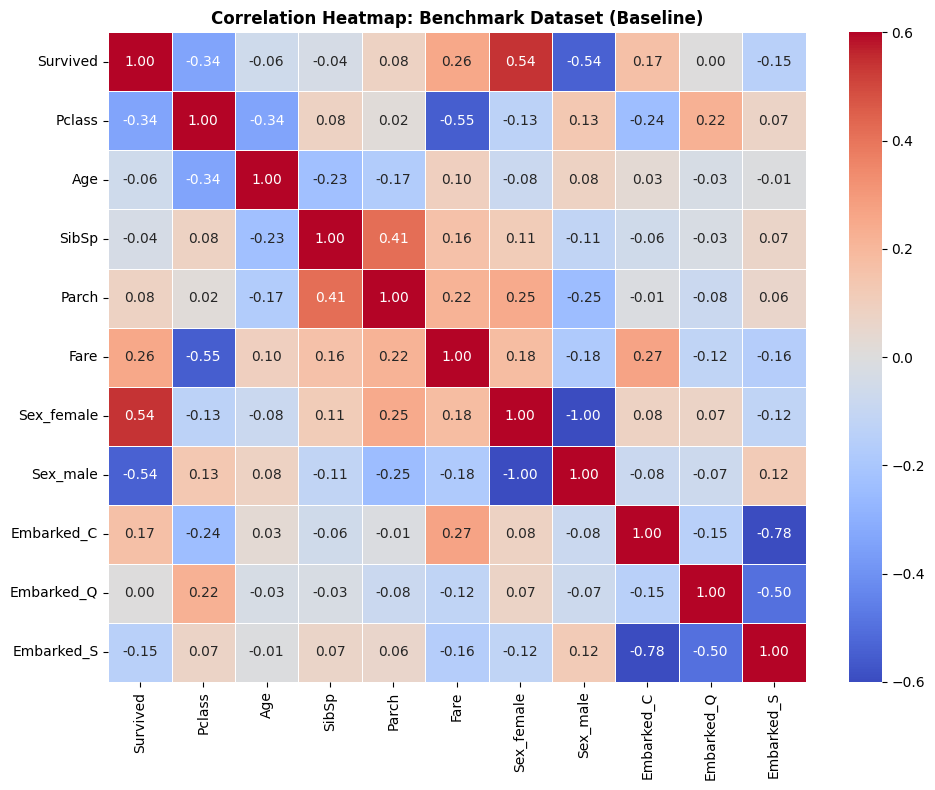

In [6]:
plt.figure(figsize=(10, 8))
sns.heatmap(
    df_benchmark.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    linewidths=0.5,
    cbar=True
)
plt.title('Correlation Heatmap: Benchmark Dataset (Baseline)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Correlation Analysis (Baseline Dataset)
---
### Correlation Matrix Takeaways:
* **Sex is the strongest individual predictor**: Correlation between `Survived` and `Sex_female` is **+0.54** (and **-0.54** for `Sex_male`), directly reflecting the historical maritime evacuation priority (*"women and children first"*).
* **Passenger Class (`Pclass`)**: A negative correlation (**-0.34**) confirms significantly lower survival rates in 3rd class relative to upper tiers, tied directly to physical lifeboat proximity and deck access.
* **Ticket Price (`Fare`)**: Shows a moderate positive correlation (**+0.26**), inherently linked to socio-economic status and cabin accommodation class.
* **Collinearity Risk**: `Sex_female` and `Sex_male` are strictly collinear ($r = -1.0$). For downstream linear modeling, one category must be omitted (`drop_first=True`) to avoid the dummy variable trap.

In [7]:
X = df_benchmark.drop('Survived', axis=1)
y = df_benchmark['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state = 42, stratify = y, test_size=0.2)

models = {
    "Logistic Regression": LogisticRegression(max_iter=500, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, min_samples_leaf=2, random_state=42),
    "XGB": XGBClassifier(n_estimators=100, max_depth=4, random_state=42, eval_metric='logloss'),
    "SVM (RBF)": SVC(C=1.0, kernel='rbf', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

print("Model benchmark (5-Fold CV accuracy):")
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring = 'accuracy')
    print(f"{name}: {scores.mean():.4f} (+/- {scores.std():.4f}")

Model benchmark (5-Fold CV accuracy):
Logistic Regression: 0.7978 (+/- 0.0190
Random Forest: 0.8133 (+/- 0.0233
XGB: 0.8049 (+/- 0.0287
SVM (RBF): 0.6939 (+/- 0.0211
KNN: 0.7318 (+/- 0.0385


## Model Benchmarking (5-Fold Stratified Cross-Validation)

Prior to advanced feature engineering, we benchmark 5 diverse model families on the naive baseline using 5-fold stratified cross-validation (`5-Fold CV Accuracy`).

Models evaluated:
1. **Logistic Regression** (Linear baseline)
2. **Random Forest** (Bagging ensemble – naturally invariant to feature scaling)
3. **XGBoost** (Gradient boosting – optimization over residuals)
4. **Support Vector Machine - RBF** (Kernel method – sensitive to unscaled variables)
5. **K-Nearest Neighbors** (Distance-based metric classifier)

### Baseline Benchmark Results:

| Algorithm | 5-Fold CV Accuracy | Std (+/-) | Engineering Assessment |
| :--- | :---: | :---: | :--- |
| **Random Forest** | **81.33%** | 0.0233 | **Top baseline performer**. Naturally robust to unscaled numerical features and able to capture basic nonlinear interactions. |
| **XGBoost** | **80.49%** | 0.0287 | Closely matches Random Forest; likely limited by default hyperparameters on a small sample size. |
| **Logistic Regression** | **79.78%** | 0.0190 | Stable, low-variance baseline, but restricted by the lack of feature scaling and interaction terms. |
| **K-Nearest Neighbors** | **73.18%** | 0.0385 | Distorted due to the massive Euclidean distance dominance of unscaled features. |
| **SVM (RBF Kernel)** | **69.39%** | 0.0211 | **Severely degraded by magnitude disparity**. Large-scale attributes completely suppress binary and smaller continuous indicators. |

> **Architectural Assessment & Next Steps**: 
> A baseline score of ~81.3% establishes our initial benchmark. The diagnostics clearly point out two core bottlenecks:
> 1. Distance- and gradient-based algorithms struggle due to unhandled scale variance.
> 2. The naive imputation strategy and discarding raw text fields (`Name`, `Ticket`, `Cabin`) likely left valuable predictive variance on the table.
>
> Before building an end-to-end transformation pipeline, we need to inspect the underlying distributions of continuous features in detail to understand where naive assumptions fall short.

## Deep Feature Profiling: Distributions, Skewness & Outliers (IQR)

We define a dedicated statistical diagnostic utility (`analyze_feature`) to inspect continuous variables:
* **Interquartile Range (IQR)** and Tukey's fences: $[Q_1 - 1.5 \cdot IQR, \; Q_3 + 1.5 \cdot IQR]$,
* **Skewness & Kurtosis metrics**,
* Three-way visualization: **Histogram + KDE**, **Tukey Boxplot**, and a **Quantile-Quantile (Q-Q) Plot** against normal distribution quantiles.

In [8]:
def analyze_feature(data, column_name):
    series = data[column_name].dropna()

    q1=series.quantile(0.25)
    q3=series.quantile(0.75)
    iqr=q3-q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    outliers = series[(series < lower_fence) | (series > upper_fence)]
    skewness = series.skew()
    kurt = series.kurtosis()

    print(f"Feature analysis: {column_name}")
    print(f"Skewness: {skewness:.3f} ({'Right skewed' if skewness > 0.5 else 'Left skewed' if skewness < -0.5 else 'Symetrical'})")
    print(f"Kurtosis: {kurt:.3f}")
    print(f"Outlier threshold (1.5*IQR): [{lower_fence:.2f}, {upper_fence:.2f}]")
    print(f"Outlier count: {len(outliers)} ({len(outliers) / len(series) * 100:.2f}% of data)")
    print(40*'-')

    fig, axes = plt.subplots(1, 3, figsize= (18,5))

    sns.histplot(series, kde=True, ax=axes[0], color='royalblue', bins=30)
    axes[0].axvline(series.mean(), color='red', linestyle='--', label=f'Mean ({series.mean():.1f})')
    axes[0].axvline(series.median(), color='green', linestyle='-', label=f'Median ({series.median():.1f})')
    axes[0].set_title(f'Distribution {column_name} (Hist + KDE)', fontsize=12)
    axes[0].legend()
    
    sns.boxplot(x=series, ax=axes[1], color='lightseagreen', flierprops=dict(marker='o', markersize=4, markerfacecolor='crimson'))
    axes[1].axvline(lower_fence, color='green', linestyle=':', label='Upper whisker')
    axes[1].axvline(upper_fence, color='crimson', linestyle=':', label='Lower whisker')
    axes[1].set_title(f'Boxplot', fontsize=12)
    axes[1].legend()
    
    stats.probplot(series, dist="norm", plot=axes[2])
    axes[2].set_title('Q-Q Plot', fontsize=12)
    axes[2].get_lines()[0].set_markerfacecolor('royalblue')
    axes[2].get_lines()[0].set_markersize(4)
    axes[2].get_lines()[1].set_color('red')
    
    plt.tight_layout()
    plt.show()

Feature analysis: Fare
Skewness: 4.787 (Right skewed)
Kurtosis: 33.398
Outlier threshold (1.5*IQR): [-26.72, 65.63]
Outlier count: 116 (13.02% of data)
----------------------------------------


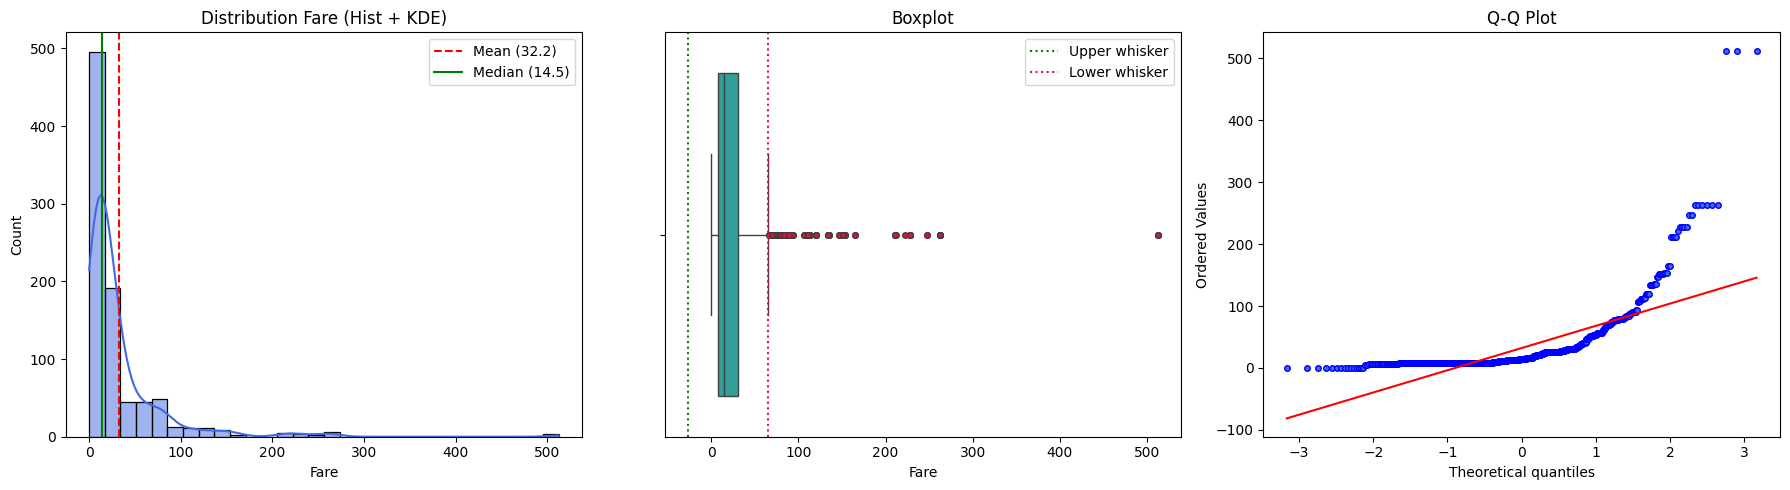

Feature analysis: Age
Skewness: 0.389 (Symetrical)
Kurtosis: 0.178
Outlier threshold (1.5*IQR): [-6.69, 64.81]
Outlier count: 11 (1.54% of data)
----------------------------------------


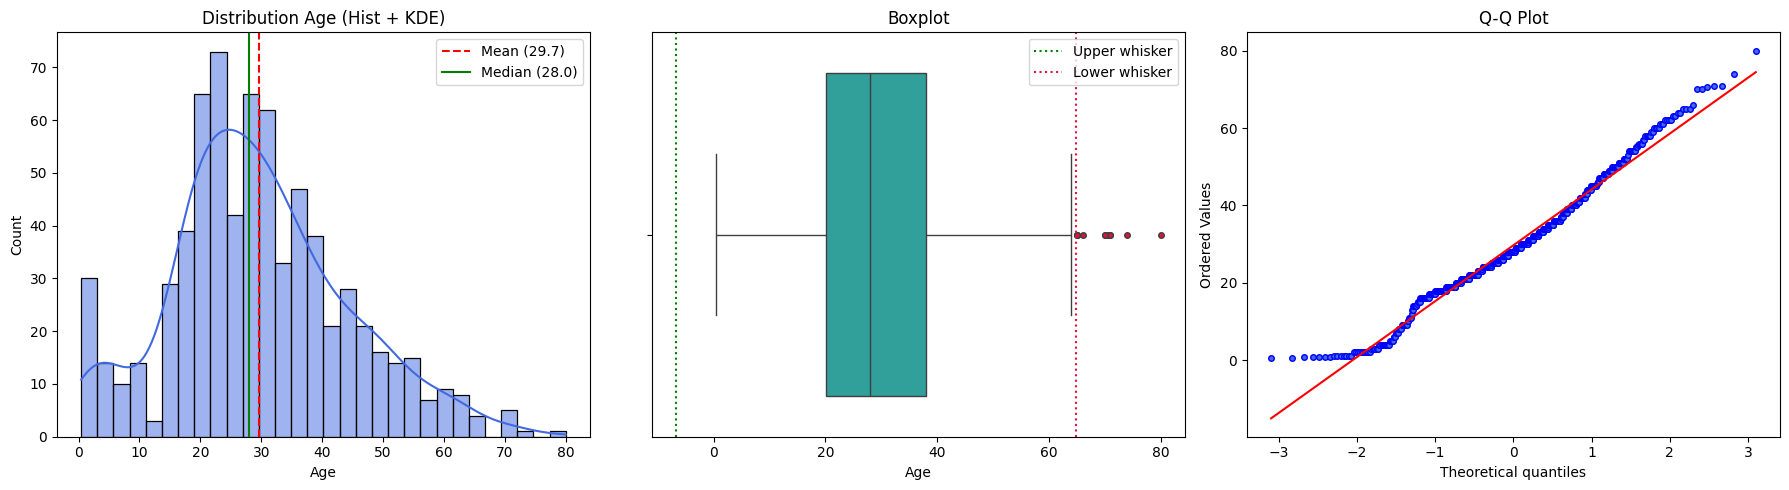

Feature analysis: SibSp
Skewness: 3.695 (Right skewed)
Kurtosis: 17.880
Outlier threshold (1.5*IQR): [-1.50, 2.50]
Outlier count: 46 (5.16% of data)
----------------------------------------


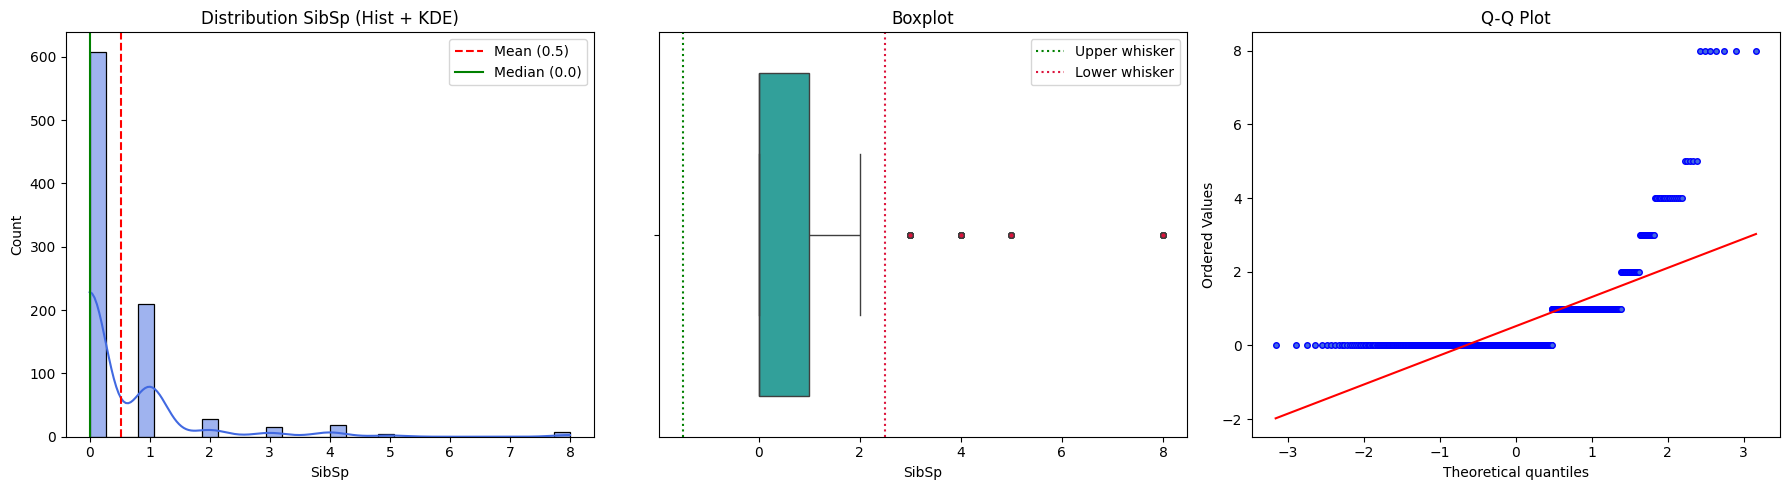

Feature analysis: Parch
Skewness: 2.749 (Right skewed)
Kurtosis: 9.778
Outlier threshold (1.5*IQR): [0.00, 0.00]
Outlier count: 213 (23.91% of data)
----------------------------------------


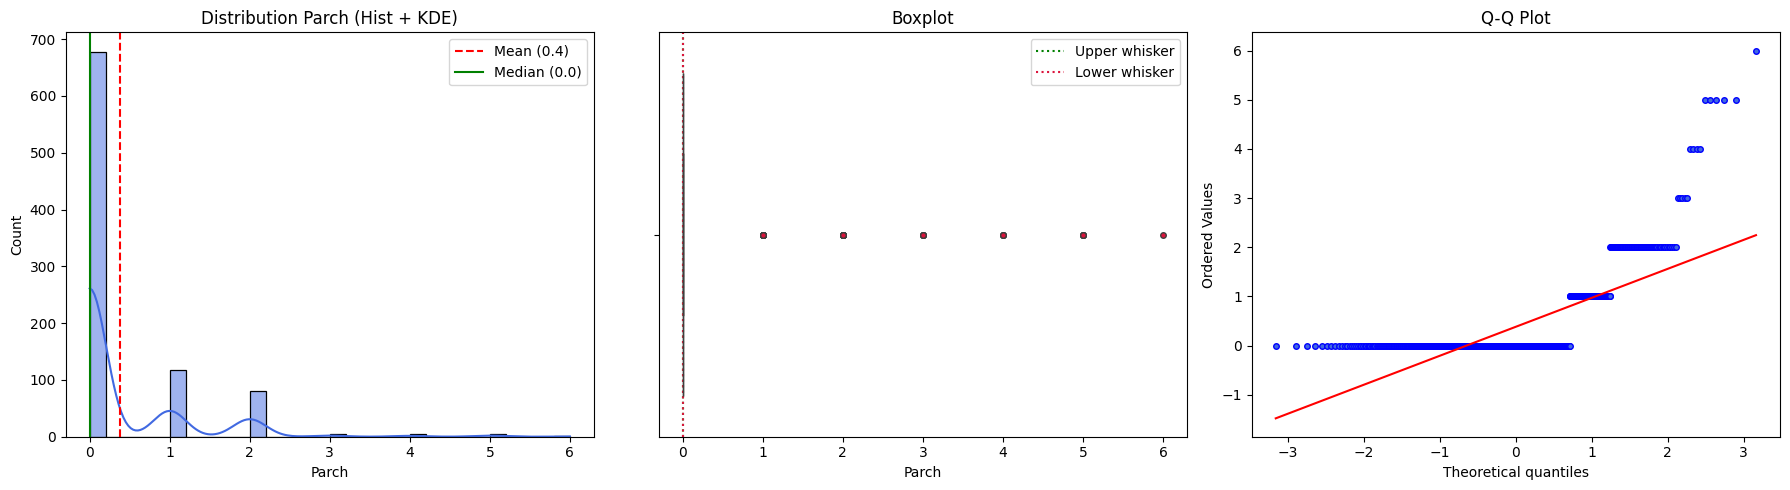

In [9]:
analyze_feature(df, 'Fare')
analyze_feature(df, 'Age')
analyze_feature(df, 'SibSp')
analyze_feature(df, 'Parch')

In [10]:
shared_tickets = df[df.duplicated(subset=['Ticket'], keep=False)].copy()

shared_tickets = shared_tickets.sort_values(by='Ticket')

columns_to_show = ['Ticket', 'Name', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Survived', 'Cabin']

print(f"Numbers of passengers traveling on shared ticket: {len(shared_tickets)}")
print(f"Number of unique shared tickets: {shared_tickets['Ticket'].nunique()}")

shared_tickets[columns_to_show].head(20)

Numbers of passengers traveling on shared ticket: 344
Number of unique shared tickets: 134


,Ticket,Name,Pclass,Sex,Age,SibSp,Parch,Fare,Survived,Cabin
257,110152,"Cherry, Miss. Gladys",1,female,30.0,0,0,86.5000,1,B77
759,110152,"Rothes, the Countess. of (Lucy Noel Martha Dye...",1,female,33.0,0,0,86.5000,1,B77
504,110152,"Maioni, Miss. Roberta",1,female,16.0,0,0,86.5000,1,B79
262,110413,"Taussig, Mr. Emil",1,male,52.0,1,1,79.6500,0,E67
558,110413,"Taussig, Mrs. Emil (Tillie Mandelbaum)",1,female,39.0,1,1,79.6500,1,E67
585,110413,"Taussig, Miss. Ruth",1,female,18.0,0,2,79.6500,1,E68
110,110465,"Porter, Mr. Walter Chamberlain",1,male,47.0,0,0,52.0000,0,C110
475,110465,"Clifford, Mr. George Quincy",1,male,NaN,0,0,52.0000,0,A14
523,111361,"Hippach, Mrs. Louis Albert (Ida Sophia Fischer)",1,female,44.0,0,1,57.9792,1,B18
329,111361,"Hippach, Miss. Jean Gertrude",1,female,16.0,0,1,57.9792,1,B18


### Diagnostic Insights: `Fare` vs `Age`

#### 1. `Fare` Anomalies & Hypotheses:
* **Observations**:
  * Extreme right-tail skewness (4.787) and extreme leptokurtic distribution (kurtosis 33.40).
  * 116 data points (~13.0%) fall above the upper Tukey fence ($65.63).
* **Domain Context & Hypotheses**:
  * Passenger records suggest that ticket prices were frequently logged as **group or family fares** rather than individual costs.
  * *Action item*: If we cross-reference ticket identifiers and family indicators (`SibSp`, `Parch`), we may derive an actual group size and calculate a normalized `FarePerPerson`.
  * *Transformation hypothesis*: A log transformation (`log1p`) could stabilize variance and make this feature significantly more useful for linear models.

#### 2. `Age` Distribution & Hypotheses:
* **Observations**:
  * Nearly symmetrical (skewness 0.389) with mild kurtosis (0.178).
  * Outliers are almost exclusively older passengers (>65 years).
* **Imputation Hypotheses**:
  * Imputing a blanket global median (~28 years) across all 177 missing values risks flattening variance and ignoring demographic nuance (e.g., children traveling with masters vs. solitary travelers in 3rd class).
  * *Action item*: Check whether social titles or passenger class stratify age distributions more effectively to provide context-driven imputation.

Raw Fare skewness: 4.787
FarePerPerson skewness: 4.381
LogFarePerPerson skewness: 0.330
Feature analysis: LogFarePerPerson
Skewness: 0.330 (Symetrical)
Kurtosis: 1.948
Outlier threshold (1.5*IQR): [0.58, 4.82]
Outlier count: 24 (2.69% of data)
----------------------------------------


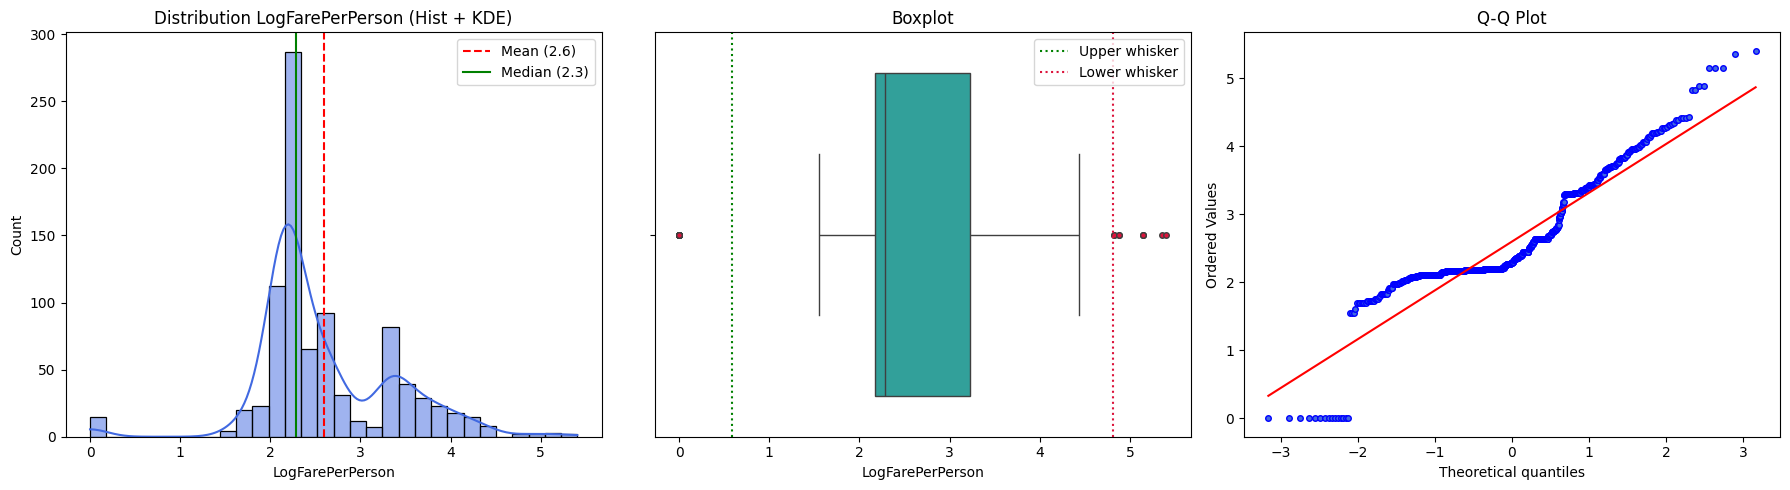

In [11]:
ticket_count = df['Ticket'].value_counts()

df['FarePerPerson'] = df['Fare'] / df['Ticket'].map(ticket_count)

df['LogFarePerPerson'] = np.log1p(df['FarePerPerson'])

print(f"Raw Fare skewness: {df['Fare'].skew():.3f}")
print(f"FarePerPerson skewness: {df['FarePerPerson'].skew():.3f}")
print(f"LogFarePerPerson skewness: {df['LogFarePerPerson'].skew():.3f}")

analyze_feature(df, 'LogFarePerPerson')

### Transformation Diagnostic: `Fare` vs. `LogFarePerPerson`

To address the severe right-tail skewness identified in the raw `Fare` attribute, we executed a two-stage transformation:
1. **Ticket-Level Normalization**: Computed `FarePerPerson = Fare / Ticket_Count` to isolate individual ticket costs from shared group purchases.
2. **Variance Stabilization**: Applied a logarithmic transformation `LogFarePerPerson = ln(1 + FarePerPerson)` to compress extreme values while preserving zero-fare entries.

#### Statistical Impact of Transformations:
* **Raw `Fare` Skewness**: **4.787** (extreme right asymmetry)
* **`FarePerPerson` Skewness**: **4.381** (frequency normalization alone slightly reduces skewness, but extreme values still dominate)
* **`LogFarePerPerson` Skewness**: **0.330** (successfully shifted into the **Symmetrical** range `[-0.5, 0.5]`)
* **Kurtosis Reduction**: Dropped from **33.398** in raw `Fare` to **1.948**, indicating a massive reduction in tail-heaviness and outlier leverage.
* **Outlier Compression (1.5 × IQR Rule)**:
  * Raw `Fare`: **116 outliers (13.02%)** exceeding $65.63.
  * `LogFarePerPerson`: **24 outliers (2.69%)** outside the fence `[0.58, 4.82]`.

#### Visual Takeaways (Tri-Panel Plot):
* **Histogram + KDE**: The distribution now closely resembles a bell curve centered around a median of **2.3** and mean of **2.6**, showing clear multimodality that likely corresponds to passenger classes.
* **Boxplot**: The interquartile range is well-balanced, and the spread of extreme values has been tightly bounded.
* **Q-Q Plot**: Demonstrates significantly closer alignment with the theoretical normal line compared to the raw feature, making `LogFarePerPerson` a viable candidate for gradient and linear models that assume normally distributed predictors.

           count      mean
GroupSize                 
1            462  0.270563
2            185  0.497297
3            128  0.632812
4             42  0.690476
5             20  0.150000
6             22  0.136364
7             19  0.473684
8              6  0.000000
11             7  0.000000


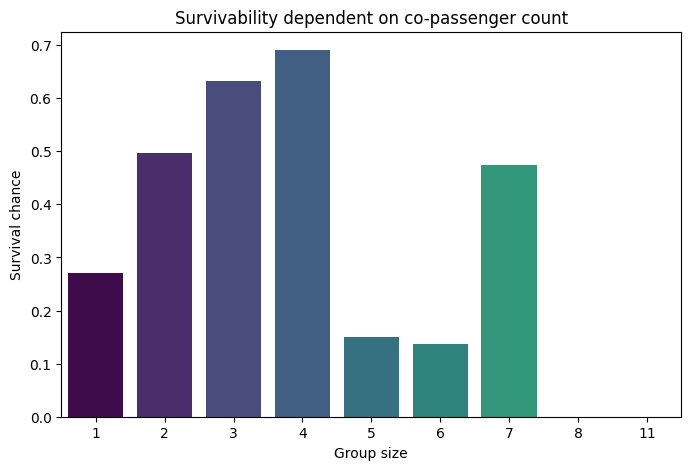

In [12]:
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1

df['TicketGroupSize'] = df['Ticket'].map(ticket_count)

df['GroupSize'] = df[['FamilySize', 'TicketGroupSize']].max(axis=1)


df = df.drop(columns=['SibSp', 'Parch', 'FamilySize', 'TicketGroupSize'])

plt.figure(figsize=(8,5))
sns.barplot(data = df, x='GroupSize', y='Survived', palette = 'viridis', hue = 'GroupSize', errorbar=None, legend = False)
plt.title("Survivability dependent on co-passenger count")
plt.ylabel("Survival chance")
plt.xlabel("Group size")

print(df.groupby('GroupSize')['Survived'].agg(['count', 'mean']))

### Feature Engineering: Traveling Group Dynamics (GroupSize)

To capture the actual traveling group size, two separate metrics are combined:
1. Biological family size: `FamilySize = SibSp + Parch + 1`.
2. Ticket sharing size: `TicketGroupSize = Ticket.map(ticket_count)`.
3. Consolidated group size: `GroupSize = max(FamilySize, TicketGroupSize)`.

The intermediate columns (`SibSp`, `Parch`, `FamilySize`, `TicketGroupSize`) are removed to prevent feature redundancy.

#### Empirical Survival Analysis
* **Solo travelers (`GroupSize = 1`)**: Represent the majority of passengers (**462** records) and show a distinctly low survival rate of **27.06%**.
* **Small groups (`GroupSize = 2 to 4`)**: Exhibit the highest survival chances, peaking at **69.05%** for parties of 4.
* **Large groups (`GroupSize >= 5`)**: Suffer a steep drop in survival probability (reaching **0.00%** for groups of 8 and 11), likely caused by logistical difficulties in coordinating evacuation.
* **The 7-passenger anomaly**: The higher survival rate of **47.37%** for `GroupSize = 7` is a statistical artifact of a small sample (**19** passengers). We leave it without custom rules, as grouping into broader categories will naturally smooth out this noise.

#### Modeling Implications
The relationship between `GroupSize` and survival chance is strongly non-linear. Binning this feature into categorical tiers (`Alone`, `SmallGroup`, `LargeGroup`) will allow linear models to capture these dynamics effectively without overfitting to small sample fluctuations.

In [13]:
df['GroupType'] = pd.cut(
    df['GroupSize'],
    bins=[0,1,4,20],
    labels=['Alone', 'SmallGroup', 'LargeGroup']
)

In [14]:
df['Title'] = df['Name'].str.extract(r',\s*([^\.]+)\.', expand=False)

print(df['Title'].value_counts())

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64


In [15]:
title_mapping = {
    'Mr': 'Mr',
    'Miss': 'Miss',
    'Mrs': 'Mrs',
    'Master': 'Master',
    'Mlle': 'Miss',  
    'Ms': 'Miss',  
    'Mme': 'Mrs'
}

df['Title'] = df['Title'].map(title_mapping).fillna('Rare')

In [16]:
title_summary = df.groupby('Title').agg(
    Count=('Survived', 'count'),
    Survivability=('Survived', 'mean'),
    Age_Median=('Age', 'median')
).reset_index()

print(title_summary)

    Title  Count  Survivability  Age_Median
0  Master     40       0.575000         3.5
1    Miss    185       0.702703        21.0
2      Mr    517       0.156673        30.0
3     Mrs    126       0.793651        35.0
4    Rare     23       0.347826        48.5


In [17]:
age_medians = df.groupby(['Title', 'Pclass'])['Age'].median().unstack()
print(age_medians)

df['Age'] = df['Age'].fillna(df.groupby(['Title', 'Pclass'])['Age'].transform('median'))
print(f"Missing values after imputation: {df['Age'].isna().sum()}")

Pclass     1     2     3
Title                   
Master   4.0   1.0   4.0
Miss    30.0  24.0  18.0
Mr      40.0  31.0  26.0
Mrs     40.0  32.0  31.0
Rare    48.5  46.5   NaN
Missing values after imputation: 0


### Feature Engineering: Title Extraction & Hierarchical Age Imputation

Inspection of the raw `Name` field reveals standardized social honorifics preceding passenger surnames. We extract these titles using a regular expression (`,\s*([^\.]+)\.`), standardize foreign synonyms (`Mlle`, `Ms`, `Mme`), and consolidate infrequent noble or professional honorifics into a single `'Rare'` category.

#### Subgroup Medians vs. Global Baseline
* The overall global median age across all passengers is **28.0** years, which fails to represent the true demographic diversity of the ship.
* Different title groups display vastly different median ages, highlighting the risk of flattening subgroup variances with a single global replacement:
  * Young boys (`Master`) present a median age of only **3.5** years, contrasting sharply with their **57.50%** survival rate.
  * Adult males (`Mr`) show a median age of **30.0** years paired with a low survival rate of **15.67%**.
  * Female cohorts (`Miss` and `Mrs`) center around median ages of **21.0** and **35.0** years, respectively.
  * The consolidated `'Rare'` group represents an older segment, with a median age of **48.5** years.

#### Cross-Class Age Stratification (`Title` × `Pclass`)
To retain granular demographic patterns without introducing arbitrary variance, we cross-reference title cohorts with passenger class (`Pclass`):

* **Class-Driven Age Gradient**: Adult groups (`Miss`, `Mr`, `Mrs`) systematically trend younger from 1st to 3rd class (e.g., unmarried females decrease from **30.0** to **18.0** years; adult males drop from **40.0** to **26.0** years).
* **Preserving Young Cohorts (`Master`)**: Young boys remain consistently young across all tiers (medians between **1.0** and **4.0** years), capturing the vital survival signal for children that a naive binary `Sex` split completely misses.
* **Handling Edge Cases (`Rare` in 3rd Class)**: Because third-class passengers hold no noble or professional titles, the cell evaluates to `NaN`. This informs a layered fallback rule:
  $$\text{Median(Title, Pclass)} \longrightarrow \text{Median(Title)} \longrightarrow \text{Global Median}$$

#### Imputation Result
Applying `transform('median')` grouped by `['Title', 'Pclass']` successfully imputes all **177** missing age entries down to **0**, preserving both demographic nuance and socio-economic variance without distorting underlying subgroup distributions.

In [18]:
cabin_count = df['Cabin'].str[0].value_counts().to_frame()
display(cabin_count)

df['HasCabin'] = df['Cabin'].notna().astype(int)

df['Deck'] = df['Cabin'].str[0].fillna('U')

display(df['Deck'].value_counts().to_frame())


,count
Cabin,
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


,count
Deck,
U,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [19]:
display(
    df.assign(RawDeck=df['Cabin'].str[0].fillna('U'))
    .groupby('RawDeck')['Survived']
    .agg(['count', 'sum', 'mean'])
)

df['Deck'] = df['Deck'].replace({'T': 'A'})

display(df['Deck'].value_counts().to_frame())

display(df.groupby('Deck')['Survived'].agg(['count', 'sum', 'mean']))

,count,sum,mean
RawDeck,,,
A,15,7,0.466667
B,47,35,0.744681
C,59,35,0.593220
D,33,25,0.757576
E,32,24,0.750000
F,13,8,0.615385
G,4,2,0.500000
T,1,0,0.000000
U,687,206,0.299854


,count
Deck,
U,687
C,59
B,47
D,33
E,32
A,16
F,13
G,4


,count,sum,mean
Deck,,,
A,16,7,0.437500
B,47,35,0.744681
C,59,35,0.593220
D,33,25,0.757576
E,32,24,0.750000
F,13,8,0.615385
G,4,2,0.500000
U,687,206,0.299854


### Feature Engineering: Cabin Extraction and Deck Grouping (`HasCabin`, `Deck`)

The raw `Cabin` attribute contains missing values in over **77%** of rows, making it unusable in its raw state without preprocessing. Rather than discarding the column entirely, we extract the initial letter of each record as a categorical proxy (`Deck`) and treat missing entries as an explicit category (`'U'` for Unknown). In parallel, we create a binary indicator (`HasCabin`) to flag whether a cabin was recorded.

#### Findings from Aggregated Outputs
* **Presence vs. Absence**: Passengers with an assigned cabin show higher survival rates across all individual letter categories—ranging from over **43%** for `A` to over **75%** for `D`—compared to the `'U'` category, which sits at under **30%** (206 of 687 survivors).
* **Consolidation of Group `T`**: Category `T` contains only **1** passenger (a non-survivor). Leaving an isolated single-observation category creates high variance and singular dummy columns during one-hot encoding; mapping `T` to `A` eliminates this single-instance category.

#### Expected Impact on Estimators
* **Linear Models (Logistic Regression, Linear SVM)**:
  * Eliminating the single-count category `T` avoids near-zero variance features and reduces the risk of unstable weight penalties under L1/L2 regularization.
  * Adding `HasCabin` gives linear models a direct binary coefficient rather than forcing them to approximate passenger standing solely through `Pclass` and `Fare`.
* **Tree-Based Ensembles (Random Forest, XGBoost)**:
  * Categorizing `Deck` into low-cardinality values allows decision trees to isolate high-survival passenger subsets in fewer splits, preserving tree depth for other feature interactions.

In [20]:
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
print(f"Missing values in 'Embarked' column after imputation: {df['Embarked'].isna().sum()}")

Missing values in 'Embarked' column after imputation: 0


In [21]:
cols_to_drop = ['PassengerId', 'Name', 'Ticket', 'Cabin', 'Fare']
df = df.drop(columns = cols_to_drop)

print("Missing values in dataset:")
print(df.isna().sum())

Missing values in dataset:
Survived            0
Pclass              0
Sex                 0
Age                 0
Embarked            0
FarePerPerson       0
LogFarePerPerson    0
GroupSize           0
GroupType           0
Title               0
HasCabin            0
Deck                0
dtype: int64


In [22]:
df['Sex'] = df['Sex'].map({'female':0, 'male':1})

cat_cols = ['Pclass', 'Title', 'GroupType', 'Embarked', 'Deck']

df = pd.get_dummies(df, columns=cat_cols, drop_first=False, dtype=int)

print(df.dtypes)

Survived                  int64
Sex                       int64
Age                     float64
FarePerPerson           float64
LogFarePerPerson        float64
GroupSize                 int64
HasCabin                  int64
Pclass_1                  int64
Pclass_2                  int64
Pclass_3                  int64
Title_Master              int64
Title_Miss                int64
Title_Mr                  int64
Title_Mrs                 int64
Title_Rare                int64
GroupType_Alone           int64
GroupType_SmallGroup      int64
GroupType_LargeGroup      int64
Embarked_C                int64
Embarked_Q                int64
Embarked_S                int64
Deck_A                    int64
Deck_B                    int64
Deck_C                    int64
Deck_D                    int64
Deck_E                    int64
Deck_F                    int64
Deck_G                    int64
Deck_U                    int64
dtype: object


### Final Imputation and Categorical Encoding

We finalize data preprocessing by resolving the remaining missing values and encoding discrete attributes for downstream modeling:

* **Mode Imputation for `Embarked`**: With only **2** missing records (~**0.2%** of the dataset), the column is imputed using its empirical mode (`'S'`), reducing missing entries to **0** without distorting distribution balance.
* **Full One-Hot Encoding (`drop_first=False`)**: Categorical predictors (`Pclass`, `Title`, `GroupType`, `Embarked`, `Deck`) are transformed into binary indicators (`dtype=int`). We deliberately retain all dummy columns so that every individual level can be evaluated in the subsequent correlation matrix against `Survived`.
* **Subsequent Correlation Diagnostics**: Calculating pairwise correlations across the expanded feature space allows us to verify whether the newly engineered indicators provide clearer linear relationships with the target variable compared to the raw features.

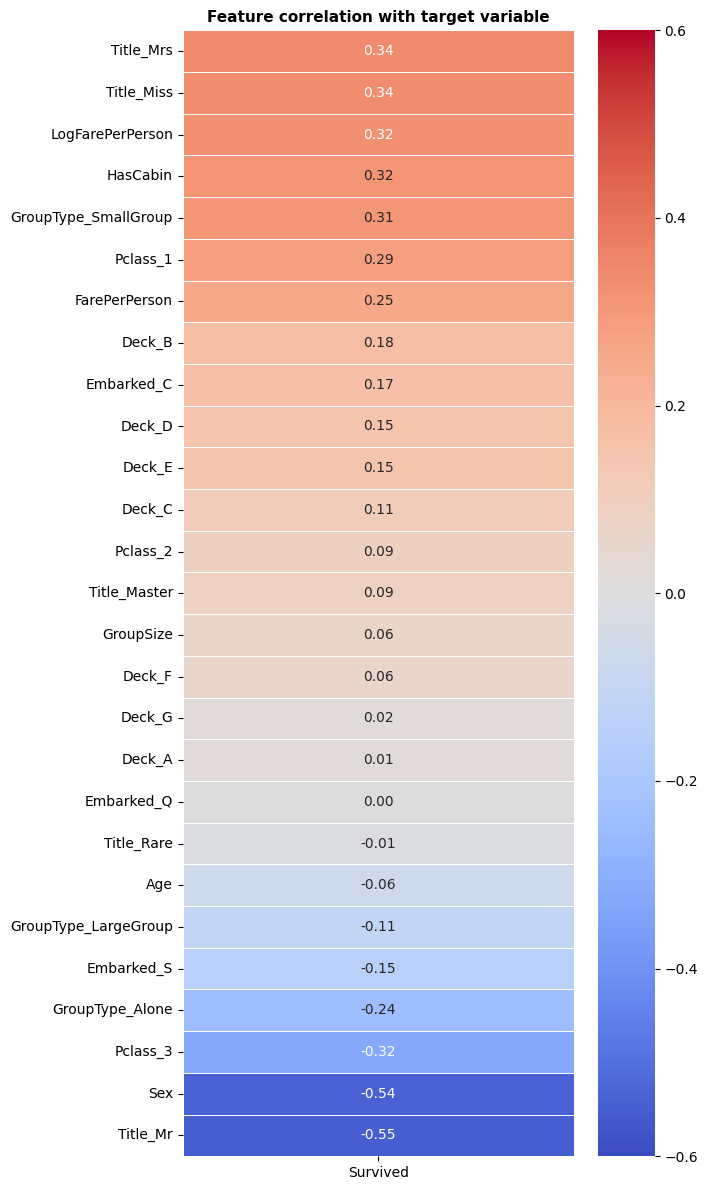

In [23]:
df_corr = df.drop(['Deck_U'], axis=1)

corr_target = df_corr.corr()[['Survived']].drop(index='Survived').sort_values(by='Survived', ascending=False)

plt.figure(figsize=(7, 12))
sns.heatmap(
    corr_target,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    linewidths=0.5,
    cbar=True,
)
plt.title(
    'Feature correlation with target variable',
    fontsize=11,
    fontweight='bold',
)
plt.tight_layout()
plt.show()

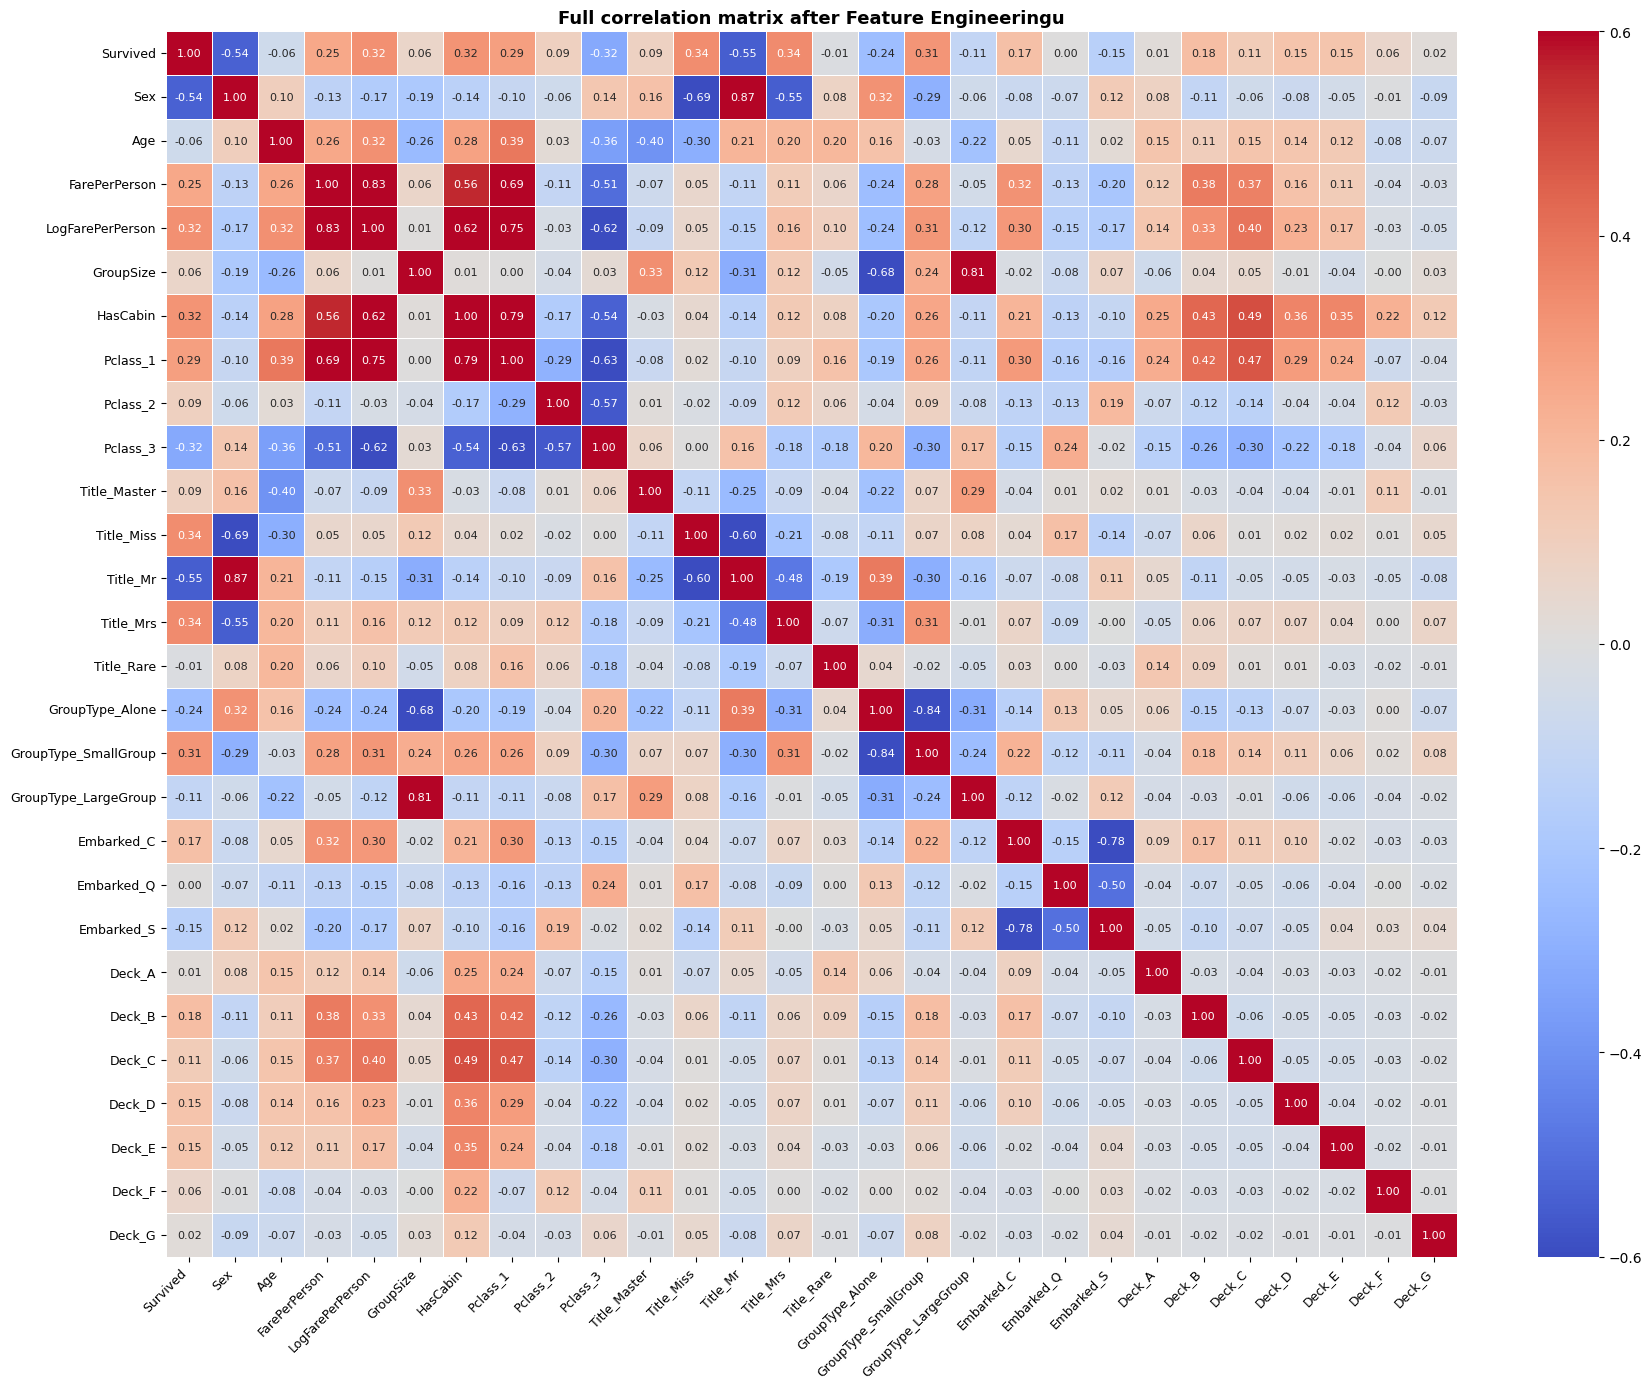

In [24]:
plt.figure(figsize=(18, 14))
sns.heatmap(
    df_corr.corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-0.6,
    vmax=0.6,
    linewidths=0.5,
    annot_kws={'size': 8},
)
plt.title(
    'Full correlation matrix after Feature Engineeringu',
    fontsize=13,
    fontweight='bold',
)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.show()

### Correlation Profiling & Feature Redundancy Diagnostics

Following the complete transformation and one-hot encoding pipeline, we examine both the pairwise collinearity matrix and feature-target correlations against `Survived`.

#### Validation of Engineered Signals
* **Title Extraction Power**: The synthesized title features provide the strongest individual correlations with survival across the dataset:
  * `Title_Mr` displays the strongest negative linear relationship at **-0.55**.
  * `Title_Mrs` and `Title_Miss` show strong positive correlations at **0.34** each.
* **Cabin & Group Categorization**:
  * `HasCabin` achieves a positive correlation of **0.32**, outperforming individual deck tiers and validating the survival signal embedded in cabin assignment.
  * `GroupType_SmallGroup` shows a notable positive association of **0.31**, whereas `GroupType_Alone` demonstrates a clear negative correlation of **-0.24**. This confirms that discretizing group dynamics successfully exposed the non-linear relationship that continuous `GroupSize` (**0.06**) obscured.
* **Normalized Financial Indicator**: `LogFarePerPerson` achieves a correlation of **0.32** with survival, markedly exceeding raw `FarePerPerson` (**0.25**) and demonstrating that variance stabilization enhanced the linear connection with the target.

#### Redundancy of `Sex` vs. Value Added by `Title`
* **Limitation of Raw `Sex`**: Binary gender treats all male passengers identically, masking the critical survival distinction between adult men (`Mr`: **15.67%** survival, median age **30.0**) and young boys (`Master`: **57.50%** survival, median age **3.5**).
* **Granular Demographic Signal**: `Title` simultaneously encodes biological sex, life stage, and social status. It captures age stratification across female cohorts (`Miss` at **21.0** years vs. `Mrs` at **35.0** years) and isolates older, distinguished travelers under `Rare` (median age **48.5**).
* **Exclusion Rationale**: Because `Title` strictly subsumes gender while providing higher-resolution demographic splits, retaining the binary `Sex` column adds redundant noise without new variance. Dropping `Sex` streamlines the feature space and prevents collinearity issues in linear models without any loss of predictive signal.